In [1]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.lines import Line2D

from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from subprocess import run, PIPE
import sys
import os
from sklearn.neighbors import KernelDensity
import gc
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [2]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [3]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [4]:
latitude = [30,60]


In [5]:
ifs_on = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/ifs_2.8km_on_30-60N_temporal_corr_nonbinary.nc')['tp']

ifs_off = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/ifs_2.8km_off_30-60N_temporal_corr_nonbinary.nc')['tp']
ifs_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/ifs_cycle3_30-60N_temporal_corr_nonbinary.nc')['tp']
ifs_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/ifs_cycle4_1990-2020_30-60N_temporal_corr_nonbinary.nc')['tp']
icon_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/icon_cycle3_30-60N_temporal_corr_nonbinary.nc')['pr']
icon_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/icon_cycle4_30-60N_temporal_corr_nonbinary.nc')['pr']
cesm2 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/cesm2_1850-2014_ens_30-60N_temporal_corr_nonbinary.nc')['PRECT']
imerg = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/imerg_30-60N_temporal_corr_nonbinary.nc')['precipitation']
#ifs_cycle4 = ifs_cycle4.isel(year=slice(0,30))
#ifs_cycle4 = ifs_cycle4.stack(sample=("year", "time"))
icon_cycle4 = icon_cycle4.isel(year=slice(0,5))
#icon_cycle4 = icon_cycle4.stack(sample=("year", "time"))



In [7]:
print(icon_cycle3)

<xarray.DataArray 'pr' (year: 5, cell: 2299980)> Size: 46MB
[11499900 values with dtype=float32]
Coordinates:
  * year     (year) int64 40B 2020 2021 2022 2023 2024
    lon      (cell) float64 18MB ...
    lat      (cell) float64 18MB ...
Dimensions without coordinates: cell


In [6]:
land_sea_ifs_high = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_2.8km_deep_off/ifs_hpx2048_lsm_30-60N.nc')['lsm']
land_sea_ifs_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_4.4-FESOM_5/IFS_cycle3_lsm_30-60N.nc')['lsm']
land_sea_ifs_zoom9 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/IFS_zoom9/30-60N_ifs_hpx512_lsm.nc')['lsm']
land_sea_icon_zoom10 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/ICON_zoom10/icon_cycle3_lsm_30-60N.nc')['ocean_fraction_surface']
land_sea_icon_zoom9 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/NextGEMS/ICON_zoom9/30-60N_ICON_ngc4008_ocean_fraction_surface_zoom9.nc')['ocean_fraction_surface']
land_sea_imerg = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/IMERG/clean/30-60N_fixgrid_GPM_IMERG_LandSeaMask.2.nc4')['landseamask']
land_sea_imerg = land_sea_imerg.assign_coords(lat=imerg.lat, lon=imerg.lon)
land_sea_cesm2 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/CESM2/precip/24H/mask.nc')['MASK']
land_sea_cesm2 = land_sea_cesm2[0,:,:]
indexer = ((land_sea_cesm2.lat>=latitude[0]) & (land_sea_cesm2.lat<=latitude[1]))
land_sea_cesm2 = land_sea_cesm2.where(indexer,drop=True)
land_sea_cesm2 = land_sea_cesm2.assign_coords(lat=cesm2.lat, lon=cesm2.lon)

ifs_on_land = ifs_on.where(land_sea_ifs_high > 0, np.nan)
ifs_off_land = ifs_off.where(land_sea_ifs_high > 0, np.nan)
ifs_cycle3_land = ifs_cycle3.where(land_sea_ifs_cycle3 > 0, np.nan)
ifs_cycle4_land = ifs_cycle4.where(land_sea_ifs_zoom9 > 0, np.nan)
icon_cycle3_land = icon_cycle3.where(land_sea_icon_zoom10 < 1, np.nan)
icon_cycle4_land = icon_cycle4.where(land_sea_icon_zoom9 < 1, np.nan)
imerg_land = imerg.where(land_sea_imerg < 100, np.nan)
cesm2_land = cesm2.where(land_sea_cesm2 > 0, np.nan)


In [7]:
print(icon_cycle3[0,:])

<xarray.DataArray 'pr' (cell: 2299980)> Size: 9MB
array([0.031069, 0.121736, 0.325214, ..., 0.04141 , 0.061037, 0.023385],
      dtype=float32)
Coordinates:
    year     int64 8B 2020
    lon      (cell) float64 18MB 56.16 55.99 56.07 56.12 ... 270.0 270.0 270.0
    lat      (cell) float64 18MB 30.04 30.04 30.04 30.09 ... 41.71 41.71 41.76
Dimensions without coordinates: cell


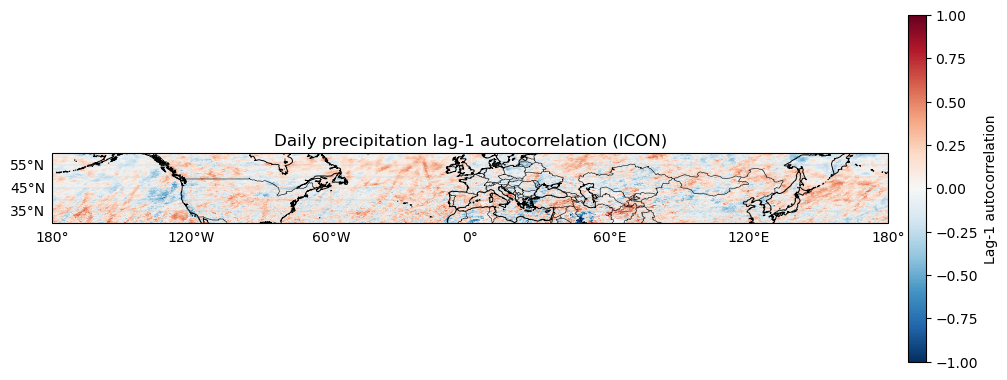

In [8]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

da = ifs_on - ifs_off





# Plot (unstructured grid -> scatter)
fig = plt.figure(figsize=(13, 5))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-180, 180, 30, 60], crs=ccrs.PlateCarree())

ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)
gl = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)
gl.top_labels = False
gl.right_labels = False

sc = ax.scatter(
    da["lon"].values,
    da["lat"].values,
    c=da.values,
    s=1.0,                 # increase if points look too small
    cmap="RdBu_r",
    vmin=-1, vmax=1,       # typical autocorr range; remove if your values differ
    transform=ccrs.PlateCarree(),
    rasterized=True,
)

cb = plt.colorbar(sc, ax=ax, pad=0.02, shrink=0.9)
cb.set_label("Lag-1 autocorrelation")

title = "Daily precipitation lag-1 autocorrelation (ICON)"

ax.set_title(title)

#plt.tight_layout()
plt.show()

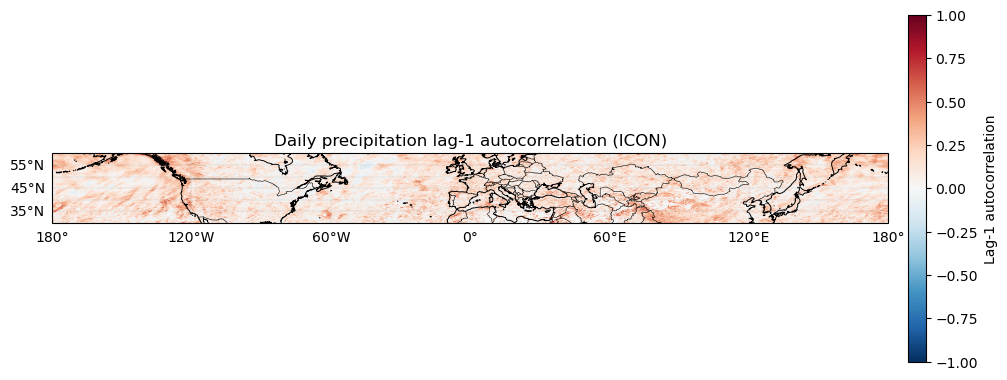

In [9]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

da = icon_cycle4[0,:]





# Plot (unstructured grid -> scatter)
fig = plt.figure(figsize=(13, 5))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-180, 180, 30, 60], crs=ccrs.PlateCarree())

ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)
gl = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)
gl.top_labels = False
gl.right_labels = False

sc = ax.scatter(
    da["lon"].values,
    da["lat"].values,
    c=da.values,
    s=1.0,                 # increase if points look too small
    cmap="RdBu_r",
    vmin=-1, vmax=1,       # typical autocorr range; remove if your values differ
    transform=ccrs.PlateCarree(),
    rasterized=True,
)

cb = plt.colorbar(sc, ax=ax, pad=0.02, shrink=0.9)
cb.set_label("Lag-1 autocorrelation")

title = "Daily precipitation lag-1 autocorrelation (ICON)"

ax.set_title(title)

#plt.tight_layout()
plt.show()

In [7]:
ifs_cycle3_land = ifs_cycle3_land.stack(sample=("year", "value"))
ifs_cycle4_land = ifs_cycle4_land.stack(sample=("year", "value"))
icon_cycle3_land = icon_cycle3_land.stack(sample=("year", "cell"))
icon_cycle4_land = icon_cycle4_land.stack(sample=("year", "cell"))
imerg_land = imerg_land.stack(sample=("year", "lat", "lon"))
cesm2_land = cesm2_land.stack(sample=("member", "year", "lat", "lon"))

In [8]:
ifs_on_land = ifs_on_land.where(~ifs_on_land.isnull(), drop=True)
ifs_off_land = ifs_off_land.where(~ifs_off_land.isnull(), drop=True)
ifs_cycle3_land = ifs_cycle3_land.where(~ifs_cycle3_land.isnull(), drop=True)
ifs_cycle4_land = ifs_cycle4_land.where(~ifs_cycle4_land.isnull(), drop=True)
icon_cycle3_land = icon_cycle3_land.where(~icon_cycle3_land.isnull(), drop=True)
icon_cycle4_land = icon_cycle4_land.where(~icon_cycle4_land.isnull(), drop=True)
imerg_land = imerg_land.where(~imerg_land.isnull(), drop=True)
cesm2_land = cesm2_land.where(~cesm2_land.isnull(), drop=True)


In [9]:
#For IMERG weighting
# 1D cos(lat) weights
lat_rad = np.deg2rad(imerg.lat)
coslat = np.cos(lat_rad)                   # dims: ['lat']

w_lat = xr.DataArray(
    coslat,
    dims=['lat'],
    coords={'lat': imerg.lat}
)

# Broadcast to (lat, lon)
w_imerg_2d = w_lat.broadcast_like(land_sea_imerg)
# Mask to land only (same land mask you use for imerg_land)
w_imerg_2d = w_imerg_2d.where(land_sea_imerg < 100)
#w_imerg_2d = w_imerg_2d / w_imerg_2d.sum()
# Broadcast spatial weights to (year, lat, lon):
w_imerg_full = xr.DataArray(
    np.broadcast_to(w_imerg_2d.values, imerg.shape),
    dims=imerg.dims,
    coords=imerg.coords,
)
print(imerg.shape)
print(imerg.dims)
print(imerg.coords)
w_imerg_land = w_imerg_full.where(land_sea_imerg < 100, np.nan)

# Stack in exactly the same way as imerg_land
w_imerg_land = w_imerg_land.stack(sample=("year", "lat", "lon"))
print(w_imerg_land)
# Drop weights where the data is NaN to keep alignment
w_imerg_land = w_imerg_land.where(~imerg_land.isnull(), drop=True)
#w_imerg = w_imerg_land.values.ravel()


(10, 300, 3600)
('year', 'lat', 'lon')
Coordinates:
  * year     (year) int64 80B 2014 2015 2016 2017 2018 2019 2020 2021 2022 2023
  * lon      (lon) float32 14kB -179.9 -179.9 -179.8 ... 179.8 179.8 179.9
  * lat      (lat) float32 1kB 30.05 30.15 30.25 30.35 ... 59.75 59.85 59.95
<xarray.DataArray (sample: 10800000)> Size: 43MB
array([nan, nan, nan, ..., nan, nan, nan], dtype=float32)
Coordinates:
  * sample   (sample) object 86MB MultiIndex
  * year     (sample) int64 86MB 2014 2014 2014 2014 ... 2023 2023 2023 2023
  * lat      (sample) float32 43MB 30.05 30.05 30.05 30.05 ... 59.95 59.95 59.95
  * lon      (sample) float32 43MB -179.9 -179.9 -179.8 ... 179.8 179.8 179.9


In [10]:
print(w_imerg_land)

<xarray.DataArray (sample: 5766389)> Size: 23MB
array([0.8655888 , 0.8655888 , 0.8655888 , ..., 0.50075555, 0.50075555,
       0.50075555], dtype=float32)
Coordinates:
  * sample   (sample) object 46MB MultiIndex
  * year     (sample) int64 46MB 2014 2014 2014 2014 ... 2023 2023 2023 2023
  * lat      (sample) float32 23MB 30.05 30.05 30.05 30.05 ... 59.95 59.95 59.95
  * lon      (sample) float32 23MB -115.8 -115.8 -115.6 ... 170.3 170.4 170.6


In [11]:
# 1D cos(lat) for CESM2
lat_rad_cesm2 = np.deg2rad(cesm2.lat)
coslat_cesm2 = np.cos(lat_rad_cesm2)

w_lat_cesm2 = xr.DataArray(
    coslat_cesm2,
    dims=['lat'],
    coords={'lat': cesm2.lat}
)

# Broadcast to (lat, lon) on CESM2 land mask
w_cesm2_2d = w_lat_cesm2.broadcast_like(land_sea_cesm2)
w_cesm2_2d = w_cesm2_2d.where(land_sea_cesm2 > 0)

# Broadcast to full CESM2(domain: member, year, lat, lon)
w_cesm2_full = xr.DataArray(
    np.broadcast_to(w_cesm2_2d.values, cesm2.shape),
    dims=cesm2.dims,
    coords=cesm2.coords,
)

w_cesm2_land = w_cesm2_full.where(land_sea_cesm2 > 0, np.nan)

# Stack identically to cesm2_land
w_cesm2_land = w_cesm2_land.stack(sample=("member", "year", "lat", "lon"))

# Align mask with data
w_cesm2_land = w_cesm2_land.where(~cesm2_land.isnull(), drop=True)

x_cesm2 = cesm2_land.values.ravel()
w_cesm2 = w_cesm2_land.values.ravel()


In [12]:
print(np.median(imerg_land))


0.14155462


In [13]:
print(np.median(cesm2_land))

0.23741839809771997


In [14]:
print(np.median(ifs_off_land))

0.1541331774755011


In [15]:
print(np.median(ifs_on_land))

0.19237274542010363


In [16]:
print(np.median(icon_cycle4_land))

0.10381515519534798


In [17]:
print(np.median(icon_cycle3_land))

0.10835008


In [18]:
print(np.median(ifs_cycle3_land))

0.18535132136447577


In [19]:
print(np.median(ifs_cycle4_land))

0.1913475262854069


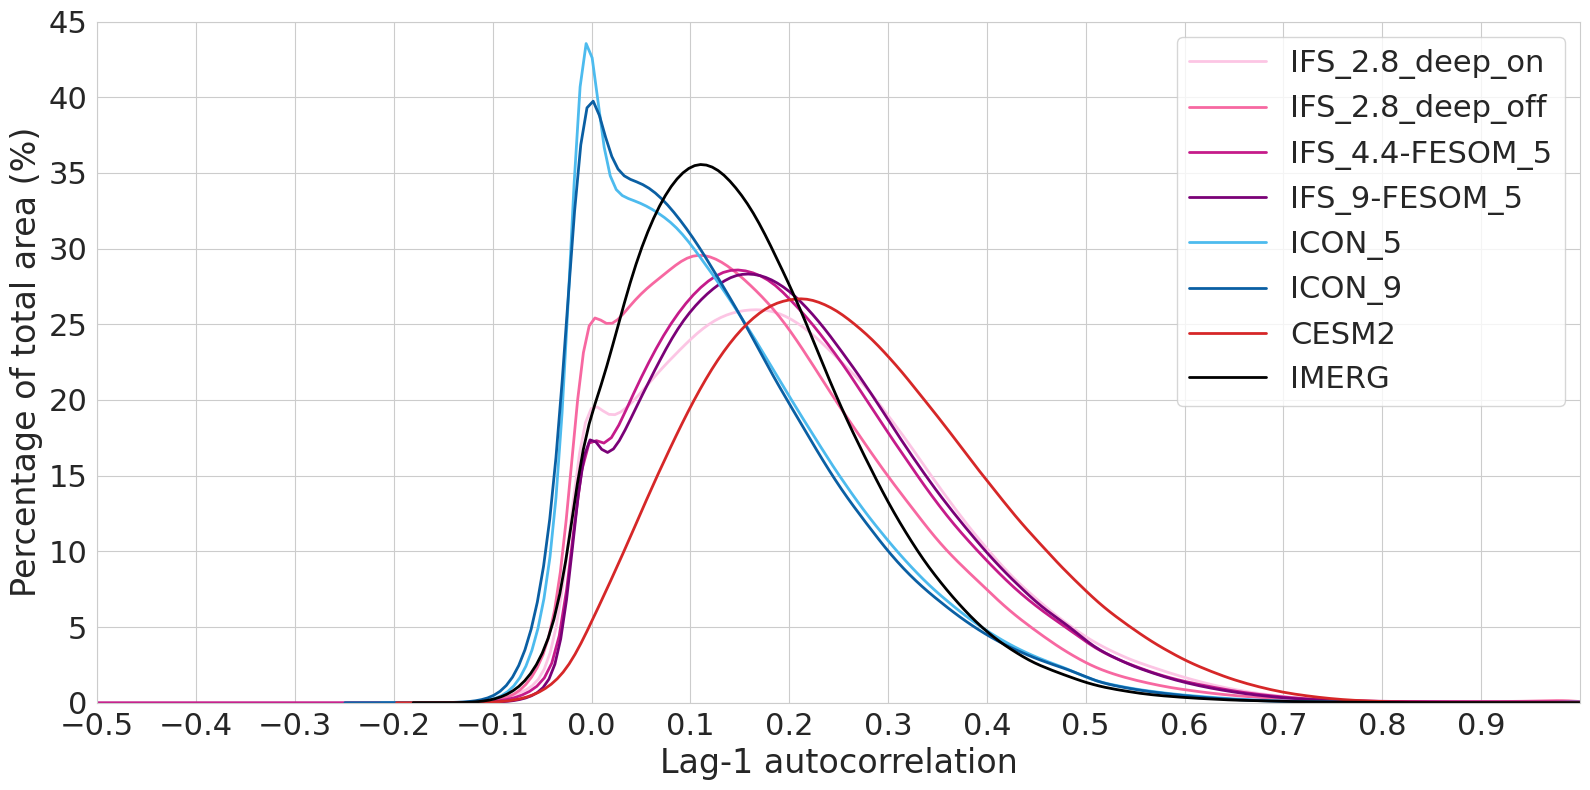

In [20]:
#with weights

# 1) Common x-range + bin width
xmin, xmax = -0.5, 1


bin_width  = 0.10


# For equal-area grids: weights = 1
def ones_like_da(da):
    return xr.ones_like(da)

datasets = [
    # IFS/ICON: equal-area → uniform weights
    (ifs_on_land,       ones_like_da(ifs_on_land),       '#FCC5E4', 'IFS_2.8_deep_on'),
    (ifs_off_land,      ones_like_da(ifs_off_land),      '#F768A1', 'IFS_2.8_deep_off'),
    (ifs_cycle3_land,   ones_like_da(ifs_cycle3_land),   '#C51B8A', 'IFS_4.4-FESOM_5'),
    (ifs_cycle4_land,   ones_like_da(ifs_cycle4_land),   '#7A0177', 'IFS_9-FESOM_5'),
    (icon_cycle3_land,  ones_like_da(icon_cycle3_land),  '#4DBBEE', 'ICON_5'),
    (icon_cycle4_land,  ones_like_da(icon_cycle4_land),  '#0A5FA3', 'ICON_9'),

    # CESM2 & IMERG: area weights from above
    (cesm2_land,        w_cesm2_land,                    '#D62728', 'CESM2'),
    (imerg_land,        w_imerg_land,                    '#000000',       'IMERG'),
]



plt.figure(figsize=(16, 8))
sns.set_style("whitegrid")
plt.rc('axes', titlesize=22)
plt.rc('axes', labelsize=18)

for data_da, wts_da, color, label in datasets:
    x = data_da.values.ravel()
    w = wts_da.values.ravel()

    sns.kdeplot(
        x=x,
        weights=w,
        bw_adjust=2.0,
        clip=(xmin, xmax),
        common_norm=False,
        fill=False,
        linewidth=2.0,
        color=color,
        label=label
    )

# 4) Rescale each line from density → percent per 0.5% bin
ax = plt.gca()
for line in ax.get_lines():
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * 100 * bin_width
    line.set_data(x_vals, y_scaled)

# 5) Labels, limits, legend
xl = 'Lag-1 autocorrelation'
ax.set_ylim(0, 45)
plt.xlabel(xl, fontsize=24)

plt.ylabel('Percentage of total area (%)', fontsize=24)


plt.xlim(xmin, xmax)
plt.tick_params(axis='both', which='major', labelsize=22)

xticks = np.arange(xmin, xmax, 0.1)
ax.set_xticks(xticks)

# build a list of Line2D handles matching your plotted lines
legend_handles = [
    Line2D([0], [0], color=color, linewidth=2.0)
    for *_, color, _ in datasets
]
# extract the labels out of your datasets tuple
legend_labels = [label for *_, _, label in datasets]

# then call legend with those handles
plt.legend(
    legend_handles,
    legend_labels,
    loc='upper right',
    prop={'size': 22},
    bbox_to_anchor=(1.0, 1.0),
    handlelength=2.5  # longer lines in legend if you like
)

plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_temporal_corr_nonbinary_histo.pdf', format='pdf',bbox_inches='tight')

plt.show()